This notebook reproduces Fig. 20. We quantify how accurately the parameters of the shuttling Hamiltonian (see `Fig11-shuttling_model.ipynb`) must be known. To this end, we design the pulses for the nominal parameters of Fig. 11, i.e., $\phi_L=0$, $\phi_R=0.8\pi$, $|\Delta_L|/t_c=1$, and $|\Delta_R|/t_c=2$, and evaluate them in a Hamiltonian in which a single parameter deviates from its nominal value by up to $\pm20\%$, while all other parameters are kept fixed.

We compare the best-performing pulse of Fig. 11 (c), $(\alpha,\beta)=(2,1.1)$, with the FAQUAD $(4,2)$ and the geometric fast-QUAD $(2,2)$. The initial and target states are the first excited eigenstates of the *true* Hamiltonian at $\varepsilon=\mp10\,t_c$, and the fidelity is obtained from the coherent time evolution. We consider two scenarios:
- Light lines: the pulse time is fixed to the optimal value $\tilde{t}_\mathrm{f}$ found for the nominal Hamiltonian (no recalibration).
- Dark lines: $t_\mathrm{f}$ is re-optimized in the miscalibrated Hamiltonian, over the same grid of pulse times $t_\mathrm{f}\in[0.1,100]\,\hbar/t_c$.

The panels show the deviation of (a) the valley-phase difference $\delta\phi\equiv\phi_R-\phi_L$, (b) the tunnel coupling $t_c$ (in units of its nominal value $t_c^{(0)}$), and (c) the left and (d) the right inter-valley couplings $|\Delta_{L,R}|$. Energies are given in units of the nominal $t_c$, and times in units of $\hbar/t_c$. The vertical gray dotted lines denote the nominal values.

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import qutip as qt
from matplotlib.lines import Line2D
from matplotlib.ticker import LogLocator, NullFormatter
from parameterrun import parameterrun
from tqdm.auto import tqdm

from HQUAD_lib.hamiltonians import two_valleys_system
from HQUAD_lib.plotting_utils import add_labels
from HQUAD_lib.QUAD_utils import compute_x_quad

# Parameters and pulses

In [2]:
tc = 1
phiL = 0.0 * np.pi
phiR = 0.8 * np.pi
DeltaL = 1
DeltaR = 2

original_params = {
    "tc": tc,
    "phiL": phiL,
    "phiR": phiR,
    "DeltaL": DeltaL,
    "DeltaR": DeltaR,
}

eps_s = np.linspace(-10, 10, 2**15 + 1)
partial_hamiltonian = np.array(
    [two_valleys_system(1, 0, 0, 0, 0, 0) for _ in range(len(eps_s))]
)

number_s = 2**20 + 1
dynamics_reduction = 8
limit_sup = 1e8

protocols = {"best": (2.0, 1.1), "FAQUAD": (4.0, 2.0), "geometric": (2.0, 2.0)}

n_tf = 300  # 300 values, as in the manuscript
tf_list = np.linspace(0.1, 100, n_tf)

n_deltas = 41  # Increase to enhance the resolution (201 values in the manuscript)
relative_deviations = np.linspace(-1, 1, n_deltas) * 0.2

In [3]:
def obtain_pulse(alpha: float, beta: float, params: dict) -> np.ndarray:
    hypermatrix = np.array([two_valleys_system(eps, **params) for eps in eps_s])
    eigvalues, eigmodes = np.linalg.eigh(hypermatrix)

    _, eps_sol = compute_x_quad(
        eigvalues,
        eigmodes,
        eps_s,
        partial_hamiltonian,
        adiabatic_state=1,
        alpha=alpha,
        beta=beta,
        n_s=number_s,
        limit_sup=limit_sup,
    )
    return eps_sol[:: 2**dynamics_reduction]


def compute_fidelity(eps_sol: np.ndarray, tf: float, params: dict) -> float:
    time = np.linspace(0, tf, len(eps_sol))

    H_0 = qt.Qobj(two_valleys_system(0, **params))
    H_driving = qt.Qobj(two_valleys_system(1, 0, 0, 0, 0, 0))
    H_T = [H_0, [H_driving, qt.coefficient(eps_sol, tlist=time)]]

    # Initial and target states are computed with the true (miscalibrated) Hamiltonian
    psi_0 = qt.Qobj(two_valleys_system(eps_s[0], **params)).eigenstates()[1][1]
    psi_target = qt.Qobj(two_valleys_system(eps_s[-1], **params)).eigenstates()[1][1]

    options = {
        "store_states": False,
        "store_final_state": True,
        "atol": 1e-10,
        "rtol": 1e-8,
        "nsteps": 10**7,
    }
    psi_f = qt.sesolve(H_T, psi_0, [0, tf], options=options).final_state

    return qt.fidelity(psi_target, psi_f) ** 2


def compute_fidelities(params: dict) -> dict:
    """
    Fidelities for all the protocols (designed for the nominal Hamiltonian) evaluated in the Hamiltonian given by params
    """
    return {
        key: np.asarray(
            parameterrun(
                compute_fidelity,
                "tf",
                tf_list,
                eps_sol=pulses[key],
                params=params,
                pbar_bool=False,
            )
        )
        for key in protocols
    }

In [4]:
# The pulses are designed for the nominal parameters
pulses = {
    key: obtain_pulse(*coordinates, params=original_params)
    for key, coordinates in protocols.items()
}

# Optimal pulse time for the nominal Hamiltonian
nominal_fidelities = compute_fidelities(original_params)
nominal_indices = {key: np.argmax(nominal_fidelities[key]) for key in protocols}

for key in protocols:
    print(
        f"{key}: 1 - F = {1 - nominal_fidelities[key][nominal_indices[key]]:.2e} at tf = "
        f"{tf_list[nominal_indices[key]]:.2f} / tc"
    )

best: 1 - F = 1.14e-06 at tf = 94.32 / tc
FAQUAD: 1 - F = 2.88e-04 at tf = 98.33 / tc
geometric: 1 - F = 4.06e-06 at tf = 98.33 / tc


# Miscalibration

In [5]:
def run_miscalibration(param_name: str, values: np.ndarray):
    """
    Fidelities when the parameter param_name of the true Hamiltonian takes the given values. Returns the fidelities with
    the pulse time re-optimized in the true Hamiltonian, and with the pulse time fixed to the nominal optimum.
    """
    optimized = {key: [] for key in protocols}
    fixed = {key: [] for key in protocols}

    for value in tqdm(values, desc=f"Varying {param_name}"):
        fidelities = compute_fidelities({**original_params, param_name: value})
        for key in protocols:
            optimized[key].append(np.max(fidelities[key]))
            fixed[key].append(fidelities[key][nominal_indices[key]])

    optimized = {key: np.array(value) for key, value in optimized.items()}
    fixed = {key: np.array(value) for key, value in fixed.items()}
    return optimized, fixed

In [6]:
# Valley phase difference (phiL = 0, so we vary phiR)
deltaPhi = phiR - phiL
deltasPhi = deltaPhi * (1 + relative_deviations)
fidelities_phi = run_miscalibration("phiR", phiL + deltasPhi)

# Tunnel coupling
deltast = tc * (1 + relative_deviations)
fidelities_tc = run_miscalibration("tc", deltast)

# Valley splittings
deltasDeltaL = DeltaL * (1 + relative_deviations)
fidelities_DeltaL = run_miscalibration("DeltaL", deltasDeltaL)

deltasDeltaR = DeltaR * (1 + relative_deviations)
fidelities_DeltaR = run_miscalibration("DeltaR", deltasDeltaR)

Varying phiR:   0%|          | 0/41 [00:00<?, ?it/s]

Varying tc:   0%|          | 0/41 [00:00<?, ?it/s]

Varying DeltaL:   0%|          | 0/41 [00:00<?, ?it/s]

Varying DeltaR:   0%|          | 0/41 [00:00<?, ?it/s]

# Plot

In [7]:
PROTOCOLS = [
    ("best", "Optimal", "#0C5DA5", "-"),
    ("FAQUAD", "FAQUAD", "#00B945", "--"),
    ("geometric", "Geometric", "#FF9500", "-."),
]


def plot_fidelities(ax, deltas, fidelities, x0, yticks):
    for key, label, color, ls in PROTOCOLS:
        # Light: t_f fixed to the nominal optimum (not recalibrated)
        ax.plot(
            deltas,
            1 - fidelities[1][key],
            color=color,
            ls=ls,
            lw=0.7,
            alpha=0.35,
            zorder=1,
        )
        # Dark: t_f re-optimized in the miscalibrated Hamiltonian
        ax.plot(
            deltas, 1 - fidelities[0][key], color=color, ls=ls, label=label, zorder=2
        )

    ax.axvline(x0, color="gray", ls=":", lw=0.8, alpha=0.6, zorder=0)
    ax.set_xlim(min(deltas), max(deltas))
    ax.set_yscale("log")
    ax.set_yticks(yticks)
    ax.yaxis.set_minor_locator(LogLocator(base=10, subs="auto", numticks=20))
    ax.yaxis.set_minor_formatter(NullFormatter())

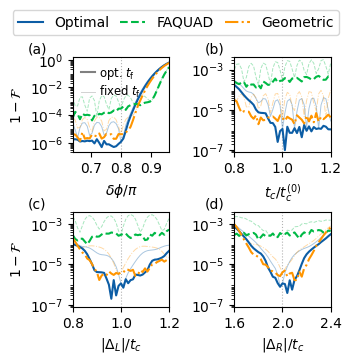

In [8]:
fig, axs = plt.subplots(2, 2, figsize=(3.4, 3.1))

plot_fidelities(
    axs[0, 0],
    deltasPhi / np.pi,
    fidelities_phi,
    deltaPhi / np.pi,
    [1e-6, 1e-4, 1e-2, 1],
)
axs[0, 0].set_xlabel(r"$\delta \phi / \pi$")
axs[0, 0].set_ylim(2e-7, 1.5)

plot_fidelities(axs[0, 1], deltast / tc, fidelities_tc, 1, [1e-7, 1e-5, 1e-3])
axs[0, 1].set_xlabel(r"$t_c/t_c^{(0)}$")

plot_fidelities(axs[1, 0], deltasDeltaL, fidelities_DeltaL, DeltaL, [1e-7, 1e-5, 1e-3])
axs[1, 0].set_xlabel(r"$|\Delta_L| / t_c$")

plot_fidelities(axs[1, 1], deltasDeltaR, fidelities_DeltaR, DeltaR, [1e-7, 1e-5, 1e-3])
axs[1, 1].set_xlabel(r"$|\Delta_R| / t_c$")
axs[1, 1].set_xticks([1.6, 2.0, 2.4])

for ax in [axs[0, 1], axs[1, 0], axs[1, 1]]:
    ax.set_ylim(8e-8, 4e-3)

for ax in axs[:, 0]:
    ax.set_ylabel(r"$1 - \mathcal{F}$")

# Gray legend for the two sets of lines: dark = re-optimized t_f, light = fixed t_f
tf_handles = [
    Line2D([], [], color="gray", lw=mpl.rcParams["lines.linewidth"]),
    Line2D([], [], color="gray", lw=0.7, alpha=0.35),
]
axs[0, 0].legend(
    tf_handles,
    [r"opt. $t_\mathrm{f}$", r"fixed $t_\mathrm{f}$"],
    loc="upper left",
    frameon=False,
    handlelength=1.2,
    handletextpad=0.4,
    labelspacing=0.2,
    borderaxespad=0.3,
    fontsize="small",
)

handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    ncols=3,
    frameon=True,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    columnspacing=0.8,
    handlelength=1.8,
)

fig.tight_layout(pad=0.3, h_pad=0.6, w_pad=0.8)
add_labels(axs.flatten(), [[-0.37, 1.08], [-0.2, 1.08]] * 2)